# Часть 3. Чтение номера (CRNN + CTC), запуск в Colab или на Kaggle

Что делает ноутбук: обучает свою CRNN (свёртки → BiLSTM → линейный слой → CTC) на кропах номеров,
сравнивает её с PaddleOCR на val, один раз считает test и **сохраняет веса** в `crnn_best.pt`
вместе с модулем `crnn_ocr.py`, чтобы другой человек мог прочитать номер тремя строками кода.

Как запускать в **Colab**: *Среда выполнения → Сменить тип среды → T4 GPU*, затем *Выполнить все*. Архив скачается сам и скопируется на Google Drive.

Как запускать на Kaggle:
1. *Settings → Accelerator* → **GPU T4 x2** или **P100**. *Internet* → **On** (нужно для скачивания датасета и PaddleOCR).
2. *Run All*, либо **Save Version → Save & Run All (Commit)**. После коммита файлы из `/kaggle/working` появятся во вкладке **Output**, оттуда их можно скачать.
3. Забрать нужно один архив `smartparking_ocr_crnn.zip` (создаётся в шаге 11).

Шаги пронумерованы как в `03_ocr.md`. Пропущенный шаг не удаляется, в нём пишется причина.

## Шаг 0. Окружение, пути, настройки

In [ ]:
import os, sys, json, random, time, subprocess, shutil, hashlib, re, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import torch, torch.nn as nn
from PIL import Image

ON_KAGGLE = Path("/kaggle/working").exists()
BASE = Path("/kaggle/working") if ON_KAGGLE else Path.cwd()
DATA_DIR = BASE / "data" / "processed" / "ocr"   # сюда пишем train/val/test.csv (как в проекте)
RAW_DIR = BASE / "hf_ocr_raw"                     # сюда скачивается датасет с Hugging Face
OUT_DIR = BASE / "ocr_outputs"                    # веса, метрики, примеры ошибок
for d in (DATA_DIR, OUT_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---- настройки ----
SEED = 42
BATCH_SIZE = 32          # по заданию 32; на T4 можно 64, но тогда это уже другой эксперимент
LR = 1e-3
MAX_EPOCHS = 40
PATIENCE = 6             # ранняя остановка по val CER
AUGMENT = True           # лёгкие аугментации: яркость/контраст, шум, размытие, сдвиг (без отражения!)
NUM_WORKERS = 2
RUN_PADDLE = True        # шаг 3: поставь False, если интернета нет или PaddleOCR не нужен
PADDLE_MAX_VAL = None    # None = весь val; число = первые N кропов (быстрее)
QUICK = False            # True = маленький прогон 2000 train / 500 val / 2 эпохи, только проверить, что всё работает

def seed_everything(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", DEVICE,
      "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "ВНИМАНИЕ: GPU не включён, обучение будет очень долгим")

torch 2.14.1+cu130 | device: cuda | Tesla T4


### Модуль `crnn_ocr.py`
Один файл со всем нужным для использования весов: алфавит, предобработка, модель, CTC-декодер, метрики и класс `CRNNReader`.
Ячейка записывает его на диск и импортирует. Именно этот файл потом уходит в архив вместе с весами.

In [ ]:
%%writefile crnn_ocr.py
"""CRNN для чтения российских автомобильных номеров (SmartParking AI, часть 3).

Использование (нужны только torch, numpy, pillow):

    from crnn_ocr import CRNNReader
    reader = CRNNReader("crnn_best.pt")      # device выбирается сам (cuda, если есть)
    reader.read("crop.png")                  # -> "A123BC77"
    reader.read_with_conf("crop.png")        # -> ("A123BC77", 0.98)
    reader.read_batch([img1, img2, ...])     # -> ["A123BC77", "K211PA69", ...]

На вход идёт УЖЕ вырезанный номер (путь к файлу, PIL.Image или numpy-массив).
Искать табличку на всей фотографии не нужно: это делает детектор из части 2.
"""
from __future__ import annotations

import numpy as np
import torch
import torch.nn as nn
from PIL import Image

ALPHABET = "0123456789ABEKMHOPCTYX"   # 22 символа
BLANK = 0                             # индекс blank для CTC
IMG_H, IMG_W = 32, 160

CHAR2IDX = {c: i + 1 for i, c in enumerate(ALPHABET)}   # 0 занят под blank
IDX2CHAR = {i + 1: c for i, c in enumerate(ALPHABET)}
NUM_CLASSES = len(ALPHABET) + 1


# --------------------------------------------------------------------------
# Предобработка: серое изображение, пропорции сохраняем, дополняем до 32x160
# --------------------------------------------------------------------------
def to_gray_pil(img, bgr: bool = False) -> Image.Image:
    """Принимает путь, PIL.Image или numpy-массив (H,W) / (H,W,3) / (H,W,4)."""
    if isinstance(img, (str, bytes)) or hasattr(img, "__fspath__"):
        img = Image.open(img)
    elif isinstance(img, np.ndarray):
        arr = img
        if arr.ndim == 3 and arr.shape[2] >= 3:
            arr = arr[:, :, :3]
            if bgr:                      # кроп из cv2 имеет порядок BGR
                arr = arr[:, :, ::-1]
        if arr.dtype != np.uint8:
            arr = np.clip(arr, 0, 255).astype(np.uint8)
        img = Image.fromarray(arr)
    return img.convert("L")


def preprocess(img, h: int = IMG_H, w: int = IMG_W, bgr: bool = False) -> np.ndarray:
    """-> uint8 массив (h, w): масштаб по высоте/ширине без искажений, справа padding."""
    g = to_gray_pil(img, bgr=bgr)
    ow, oh = g.size
    scale = min(h / oh, w / ow)
    nw, nh = max(1, round(ow * scale)), max(1, round(oh * scale))
    g = g.resize((nw, nh), Image.BILINEAR)
    arr = np.asarray(g, dtype=np.uint8)
    pad_val = int(np.median(arr))        # фон добавляем в цвет самого кропа
    canvas = np.full((h, w), pad_val, dtype=np.uint8)
    top = (h - nh) // 2
    canvas[top:top + nh, :nw] = arr
    return canvas


def to_tensor(arr_u8: np.ndarray) -> torch.Tensor:
    """uint8 (H,W) или (B,H,W) -> float32 (B,1,H,W) в диапазоне [-1, 1]."""
    x = torch.from_numpy(np.ascontiguousarray(arr_u8)).float() / 255.0
    if x.ndim == 2:
        x = x.unsqueeze(0)
    return ((x - 0.5) / 0.5).unsqueeze(1)


# --------------------------------------------------------------------------
# Модель: CNN -> BiLSTM -> Linear (-> CTC)
# --------------------------------------------------------------------------
def _conv(cin, cout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1, bias=False),
        nn.BatchNorm2d(cout),
        nn.ReLU(inplace=True),
    )


class CRNN(nn.Module):
    """Вход (B,1,32,160) -> логиты (B,T=40,num_classes)."""

    def __init__(self, num_classes: int = NUM_CLASSES, rnn_hidden: int = 192,
                 rnn_layers: int = 2, dropout: float = 0.25):
        super().__init__()
        self.cnn = nn.Sequential(
            _conv(1, 32), nn.MaxPool2d(2, 2),                       # 16 x 80
            _conv(32, 64), nn.MaxPool2d(2, 2),                      # 8 x 40
            _conv(64, 128), _conv(128, 128), nn.MaxPool2d((2, 1)),  # 4 x 40
            _conv(128, 256), _conv(256, 256), nn.MaxPool2d((2, 1)), # 2 x 40
        )
        self.rnn = nn.LSTM(256 * 2, rnn_hidden, num_layers=rnn_layers,
                           bidirectional=True, batch_first=True,
                           dropout=dropout if rnn_layers > 1 else 0.0)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(rnn_hidden * 2, num_classes)

    def forward(self, x):
        f = self.cnn(x)                                   # B,C,H,W
        b, c, h, w = f.shape
        f = f.permute(0, 3, 1, 2).reshape(b, w, c * h)    # B,T,C*H
        out, _ = self.rnn(f)
        return self.fc(self.drop(out))                    # B,T,classes


# --------------------------------------------------------------------------
# Кодирование / декодирование CTC
# --------------------------------------------------------------------------
def encode_text(text: str) -> list[int]:
    return [CHAR2IDX[c] for c in text]


def ctc_greedy_decode(logits: torch.Tensor):
    """logits (B,T,C) -> (список строк, список уверенностей)."""
    probs = logits.float().softmax(-1)
    conf, idx = probs.max(-1)                             # B,T
    idx, conf = idx.cpu().numpy(), conf.cpu().numpy()
    texts, confs = [], []
    for seq, cf in zip(idx, conf):
        chars, cs, prev = [], [], BLANK
        for k, p in zip(seq, cf):
            if k != prev and k != BLANK:
                chars.append(IDX2CHAR[int(k)])
                cs.append(float(p))
            prev = k
        texts.append("".join(chars))
        confs.append(float(np.mean(cs)) if cs else 0.0)
    return texts, confs


# --------------------------------------------------------------------------
# Метрики
# --------------------------------------------------------------------------
def edit_ops(ref: str, hyp: str):
    """Левенштейн с разбором: (замены S, пропуски D, лишние I)."""
    n, m = len(ref), len(hyp)
    d = [[0] * (m + 1) for _ in range(n + 1)]
    for i in range(n + 1):
        d[i][0] = i
    for j in range(m + 1):
        d[0][j] = j
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            cost = 0 if ref[i - 1] == hyp[j - 1] else 1
            d[i][j] = min(d[i - 1][j] + 1, d[i][j - 1] + 1, d[i - 1][j - 1] + cost)
    i, j, S, D, I = n, m, 0, 0, 0
    while i > 0 or j > 0:
        if i > 0 and j > 0 and d[i][j] == d[i - 1][j - 1] + (ref[i - 1] != hyp[j - 1]):
            S += int(ref[i - 1] != hyp[j - 1]); i -= 1; j -= 1
        elif i > 0 and d[i][j] == d[i - 1][j] + 1:
            D += 1; i -= 1
        else:
            I += 1; j -= 1
    return S, D, I


def compute_metrics(refs, hyps) -> dict:
    """CER, точность символов, Exact Match. Одни и те же для всех моделей."""
    N = S = D = I = em = 0
    for r, h in zip(refs, hyps):
        s, d, i = edit_ops(r, h)
        S += s; D += d; I += i; N += len(r)
        em += int(r == h)
    return {
        "cer": (S + D + I) / max(N, 1),            # лишние + пропущенные + заменённые
        "char_acc": (N - S - D) / max(N, 1),       # доля символов эталона, прочитанных верно
        "exact_match": em / max(len(refs), 1),     # номер целиком совпал
        "n": len(refs), "S": S, "D": D, "I": I,
    }


# --------------------------------------------------------------------------
# Удобная обёртка для использования весов другим человеком / частью 4
# --------------------------------------------------------------------------
class CRNNReader:
    def __init__(self, weights_path: str, device: str | None = None):
        self.device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
        ckpt = torch.load(weights_path, map_location="cpu", weights_only=True)
        self.alphabet = ckpt.get("alphabet", ALPHABET)
        assert self.alphabet == ALPHABET, "алфавит весов не совпадает с crnn_ocr.ALPHABET"
        self.h, self.w = ckpt.get("img_h", IMG_H), ckpt.get("img_w", IMG_W)
        self.model = CRNN(**ckpt.get("model_cfg", {}))
        self.model.load_state_dict(ckpt["model_state"])
        self.model.to(self.device).eval()
        self.info = {k: v for k, v in ckpt.items() if k not in ("model_state",)}

    @torch.no_grad()
    def read_batch_with_conf(self, imgs, bgr: bool = False, batch_size: int = 128):
        texts, confs = [], []
        for i in range(0, len(imgs), batch_size):
            arr = np.stack([preprocess(im, self.h, self.w, bgr=bgr) for im in imgs[i:i + batch_size]])
            logits = self.model(to_tensor(arr).to(self.device))
            t, c = ctc_greedy_decode(logits)
            texts += t; confs += c
        return texts, confs

    def read_batch(self, imgs, bgr: bool = False):
        return self.read_batch_with_conf(imgs, bgr=bgr)[0]

    def read_with_conf(self, img, bgr: bool = False):
        t, c = self.read_batch_with_conf([img], bgr=bgr)
        return t[0], c[0]

    def read(self, img, bgr: bool = False) -> str:
        return self.read_with_conf(img, bgr=bgr)[0]

Writing crnn_ocr.py


In [ ]:
sys.path.insert(0, str(Path.cwd()))
import importlib, crnn_ocr
importlib.reload(crnn_ocr)
from crnn_ocr import (ALPHABET, BLANK, IMG_H, IMG_W, NUM_CLASSES, CRNN, preprocess, to_tensor,
                      encode_text, ctc_greedy_decode, compute_metrics, edit_ops, CRNNReader)
print("алфавит:", ALPHABET, "| классов с blank:", NUM_CLASSES)

алфавит: 0123456789ABEKMHOPCTYX | классов с blank: 23


## Шаг 1. Проверка CSV
Если в проекте уже есть `data/processed/ocr/*.csv` с рабочими путями, берём их.
Иначе (на Kaggle так и будет) скачиваем с Hugging Face архивы `train.zip`, `val.zip`, `test.zip` датасета `AY000554/Car_plate_OCR_dataset` (~1.2 ГБ) и собираем такие же CSV:
колонки `split, image, text, width, height, valid_format`. Номер лежит в имени файла. Точные копии файлов выкидываются, а если один и тот же номер
попал в разные выборки, все его кадры переносятся в одну, чтобы не было утечки между train и val/test.

In [ ]:
def csvs_ok():
    try:
        for s in ("train", "val", "test"):
            df = pd.read_csv(DATA_DIR / f"{s}.csv")
            if len(df) == 0 or not Path(df["image"].iloc[0]).exists():
                return False
        return True
    except Exception:
        return False

def build_csvs():
    from huggingface_hub import hf_hub_download
    split_dirs = {}
    for split in ("train", "val", "test"):
        target = RAW_DIR / split
        if not target.exists() or not any(target.rglob("*.png")) and not any(target.rglob("*.jpg")):
            z = hf_hub_download(repo_id="AY000554/Car_plate_OCR_dataset", repo_type="dataset", filename=f"{split}.zip")
            target.mkdir(parents=True, exist_ok=True)
            with zipfile.ZipFile(z) as zf:
                zf.extractall(target)
            print(f"{split}.zip распакован в {target}")
        split_dirs[split] = target
    rows, seen_hash = [], set()
    for split, root in split_dirs.items():
        for p in sorted(root.rglob("*")):
            if p.suffix.lower() not in (".png", ".jpg", ".jpeg", ".bmp"):
                continue
            stem = re.split(r"[_ (\-]", p.stem)[0].upper()      # на случай суффиксов вида A123BC77_1
            h = hashlib.md5(p.read_bytes()).hexdigest()
            if h in seen_hash:                                     # точная копия файла
                continue
            seen_hash.add(h)
            try:
                with Image.open(p) as im:
                    w, hh = im.size
            except Exception:
                continue
            rows.append(dict(split=split, image=str(p), text=stem, width=w, height=hh,
                             valid_format=bool(stem) and all(c in ALPHABET for c in stem)))
    df = pd.DataFrame(rows)
    # один номер -> одна выборка (там, где у номера больше кадров), чтобы не было утечки train -> val/test
    cnt = df.groupby(["text", "split"]).size().reset_index(name="n")
    best = cnt.sort_values(["text", "n"], ascending=[True, False]).drop_duplicates("text").set_index("text")["split"]
    moved = int((df["split"] != df["text"].map(best)).sum())
    df["split"] = df["text"].map(best)
    print(f"кадров: {len(df)}, перенесено между выборками из-за одинаковых номеров: {moved}")
    for sp in ("train", "val", "test"):
        df[df.split == sp].to_csv(DATA_DIR / f"{sp}.csv", index=False)

if csvs_ok():
    print("CSV из проекта найдены, пути рабочие.")
else:
    print("Рабочих CSV нет, скачиваю датасет и собираю их...")
    build_csvs()

dfs = {s: pd.read_csv(DATA_DIR / f"{s}.csv") for s in ("train", "val", "test")}
for s, d in dfs.items():
    print(s, len(d), "| невалидных строк:", int((~d["valid_format"].astype(bool)).sum()) if "valid_format" in d else "?")
assert len(dfs["train"]) > 1000, "train пустой или это быстрый прогон: нужен полный датасет"
# обучать и оценивать только на строках, где текст целиком из алфавита
dfs = {s: d[d["text"].map(lambda t: isinstance(t, str) and len(t) > 0 and all(c in ALPHABET for c in t))].reset_index(drop=True)
       for s, d in dfs.items()}
if QUICK:
    dfs = {"train": dfs["train"].sample(2000, random_state=SEED).reset_index(drop=True),
           "val": dfs["val"].sample(500, random_state=SEED).reset_index(drop=True),
           "test": dfs["test"].sample(500, random_state=SEED).reset_index(drop=True)}
    MAX_EPOCHS = 2
print({s: len(d) for s, d in dfs.items()})
print("длина номера:", dfs["train"]["text"].str.len().value_counts().sort_index().to_dict())
print("пересечение номеров train/val:", len(set(dfs["train"].text) & set(dfs["val"].text)),
      "| train/test:", len(set(dfs["train"].text) & set(dfs["test"].text)))

Рабочих CSV нет, скачиваю датасет и собираю их...


train.zip: reconstructing file:   0%|          |  0.00B / 1.02GB            

train.zip: downloading bytes:           |  0.00B            

train.zip распакован в /content/hf_ocr_raw/train


val.zip: reconstructing file:   0%|          |  0.00B /  133MB            

val.zip: downloading bytes:           |  0.00B            

val.zip распакован в /content/hf_ocr_raw/val


test.zip: reconstructing file:   0%|          |  0.00B / 72.4MB            

test.zip: downloading bytes:           |  0.00B            

test.zip распакован в /content/hf_ocr_raw/test
кадров: 45509, перенесено между выборками из-за одинаковых номеров: 6
train 37772 | невалидных строк: 0
val 4888 | невалидных строк: 0
test 2849 | невалидных строк: 0
{'train': 37772, 'val': 4888, 'test': 2849}
длина номера: {8: 21360, 9: 16412}
пересечение номеров train/val: 0 | train/test: 0


## Шаг 1б. Первые буквы X и Y есть только в val (исправление разбиения)
В официальном разбиении датасета в train нет ни одного номера, начинающегося с X или Y, а в val их ~740. Модель никогда не видела такую первую букву и читала её с точностью 0%.
Исправление: 70% номеров на X/Y переносятся из val в train **целиком по номерам** (без утечки). Test не трогаем. Это отступление от официального split, оно записывается в отчёт.
Ячейка безопасна для повторного запуска: старые веса и кэш test переименовываются в `*_v1`.

In [ ]:
for s_ in ("train", "val", "test"):
    print(s_, dfs[s_].text.str[0].value_counts().to_dict())

# старые результаты (до исправления) не затираем
for name in ("crnn_best", "test_result"):
    old = OUT_DIR / (name + (".pt" if name == "crnn_best" else ".json"))
    new = OUT_DIR / (name + "_v1" + old.suffix)
    if old.exists() and not new.exists():
        old.rename(new); print("сохранено как", new.name)
    elif old.exists():
        old.unlink()

if not dfs["train"].text.str[0].isin(list("XY")).any():
    rng = np.random.RandomState(SEED)
    v0 = dfs["val"]
    texts = v0[v0.text.str[0].isin(list("XY"))].text.unique()
    rng.shuffle(texts)
    move_texts = set(texts[: int(len(texts) * 0.7)])
    moved = v0[v0.text.isin(move_texts)]
    dfs["train"] = pd.concat([dfs["train"], moved]).reset_index(drop=True)
    dfs["val"] = v0[~v0.text.isin(move_texts)].reset_index(drop=True)
    print("перенесено в train:", len(moved), "| train:", len(dfs["train"]), "| val:", len(dfs["val"]))
else:
    print("X/Y в train уже есть, переносить не нужно")
print("первые буквы train:", dfs["train"].text.str[0].value_counts().to_dict())
print("первые буквы val:", dfs["val"].text.str[0].value_counts().to_dict())
print("пересечение номеров train/val:", len(set(dfs["train"].text) & set(dfs["val"].text)))

train {'A': 6032, 'B': 5054, 'K': 4527, 'H': 4395, 'E': 4262, 'O': 4058, 'C': 3238, 'T': 2913, 'P': 2841, 'M': 452}
val {'A': 701, 'B': 545, 'H': 476, 'O': 465, 'K': 461, 'E': 447, 'X': 381, 'Y': 363, 'C': 348, 'T': 339, 'P': 320, 'M': 42}
test {'A': 391, 'B': 309, 'K': 301, 'H': 294, 'O': 281, 'E': 245, 'C': 203, 'X': 198, 'P': 189, 'Y': 189, 'T': 185, 'M': 64}
перенесено в train: 520 | train: 38292 | val: 4368
первые буквы train: {'A': 6032, 'B': 5054, 'K': 4527, 'H': 4395, 'E': 4262, 'O': 4058, 'C': 3238, 'T': 2913, 'P': 2841, 'M': 452, 'X': 275, 'Y': 245}
первые буквы val: {'A': 701, 'B': 545, 'H': 476, 'O': 465, 'K': 461, 'E': 447, 'C': 348, 'T': 339, 'P': 320, 'Y': 118, 'X': 106, 'M': 42}
пересечение номеров train/val: 0


## Шаг 2. Несколько кропов глазами

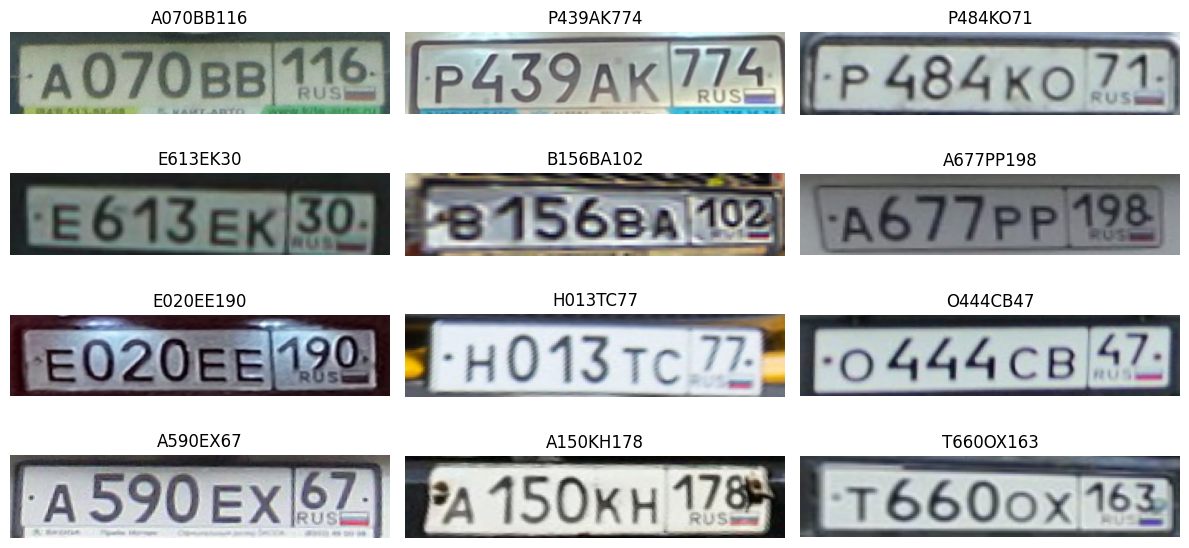

     width  height
min   73.0    16.0
50%  239.0    52.0
max  758.0   164.0
символов вне алфавита: 0


In [ ]:
import matplotlib.pyplot as plt
sample = dfs["train"].sample(12, random_state=1)
fig, axes = plt.subplots(4, 3, figsize=(12, 6))
for ax, (_, r) in zip(axes.ravel(), sample.iterrows()):
    ax.imshow(Image.open(r["image"]).convert("RGB")); ax.set_title(r["text"], fontsize=12); ax.axis("off")
plt.tight_layout(); plt.show()
sizes = dfs["train"][["width", "height"]].describe().loc[["min", "50%", "max"]]
print(sizes)
bad = [c for t in dfs["train"].text for c in t if c not in ALPHABET]
print("символов вне алфавита:", len(bad))

## Шаг 3. PaddleOCR на val (база, без своего обучения)
Установка Paddle меняет версии numpy/opencv, поэтому здесь только определяются функции, а сам прогон выполняется в ячейке **3б сразу после шага 7** (в отдельном процессе).
Скрипт читает кропы, возвращает строки; дальше метрики считаются нашей общей функцией `compute_metrics`, то же самое, что у CRNN.
Кириллические двойники (А, В, Е, К, М, Н, О, Р, С, Т, У, Х) приводятся к латинице, всё вне алфавита выбрасывается.
Если шаг не получился, в `PADDLE_STATUS` будет причина, а в таблице строка PaddleOCR останется помеченной «не запускался».

In [ ]:
PADDLE_STATUS = "не запускался"
paddle_val_metrics = None
paddle_val_preds = None

PADDLE_SCRIPT = r"""
import sys, json
paths = json.load(open(sys.argv[1]))
out_path = sys.argv[2]
preds = []
rec = None
errs = []
try:                                   # paddleocr 3.x
    from paddleocr import TextRecognition
    for name in ["en_PP-OCRv5_mobile_rec", "en_PP-OCRv4_mobile_rec", "PP-OCRv5_mobile_rec", "PP-OCRv5_server_rec"]:
        try:
            rec = ("v3", TextRecognition(model_name=name)); used = name; break
        except Exception as e:
            errs.append(f"{name}: {e}")
except Exception as e:
    errs.append(f"TextRecognition: {e}")
if rec is None:                        # paddleocr 2.x
    from paddleocr import PaddleOCR
    rec = ("v2", PaddleOCR(use_angle_cls=False, lang="en", show_log=False)); used = "PaddleOCR 2.x en"
kind, m = rec
B = 32
for i in range(0, len(paths), B):
    chunk = paths[i:i+B]
    if kind == "v3":
        res = m.predict(input=chunk, batch_size=len(chunk))
        for r in res:
            preds.append(r["rec_text"] if "rec_text" in r else "")
    else:
        for p in chunk:
            r = m.ocr(p, det=False, cls=False)
            try:
                preds.append(r[0][0][0])
            except Exception:
                preds.append("")
json.dump({"model": used, "preds": preds, "errors": errs}, open(out_path, "w"))
"""

CYR2LAT = str.maketrans({"А":"A","В":"B","Е":"E","К":"K","М":"M","Н":"H","О":"O","Р":"P","С":"C","Т":"T","У":"Y","Х":"X"})
def norm_plate(s: str) -> str:
    s = (s or "").upper().translate(CYR2LAT)
    return "".join(c for c in s if c in ALPHABET)

def run_paddle(paths):
    """Прогон PaddleOCR в отдельном процессе. Возвращает (сырой текст, нормализованный, имя модели)."""
    ok = subprocess.run([sys.executable, "-c", "import paddleocr"], capture_output=True).returncode == 0
    if not ok:
        r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "paddlepaddle", "paddleocr"],
                           capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError("pip install paddle: " + r.stderr[-400:])
    (BASE / "paddle_in.json").write_text(json.dumps(list(paths)))
    (BASE / "paddle_run.py").write_text(PADDLE_SCRIPT)
    r = subprocess.run([sys.executable, str(BASE / "paddle_run.py"),
                        str(BASE / "paddle_in.json"), str(BASE / "paddle_out.json")], capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError("paddle_run: " + r.stderr[-600:])
    res = json.loads((BASE / "paddle_out.json").read_text())
    return res["preds"], [norm_plate(x) for x in res["preds"]], res["model"]

def paddle_on_val():
    global PADDLE_STATUS, paddle_val_metrics, paddle_val_preds
    if not RUN_PADDLE:
        PADDLE_STATUS = "не запускался: RUN_PADDLE=False"; print(PADDLE_STATUS); return
    try:
        sub = dfs["val"] if PADDLE_MAX_VAL is None else dfs["val"].head(PADDLE_MAX_VAL)
        t0 = time.time()
        raw, paddle_val_preds, pname = run_paddle(sub["image"].tolist())
        paddle_val_metrics = compute_metrics(sub["text"].tolist(), paddle_val_preds)
        PADDLE_STATUS = f"ок ({pname}), {time.time()-t0:.0f} c, кропов: {len(sub)}"
        print(PADDLE_STATUS); print(paddle_val_metrics)
        print("примеры (сырое -> после нормализации -> эталон):")
        for r_, p_, t_ in list(zip(raw, paddle_val_preds, sub["text"]))[:8]:
            print(f"  {r_!r:20} -> {p_:12} | {t_}")
    except Exception as e:
        PADDLE_STATUS = f"не запускался: {type(e).__name__}: {e}"
        print(PADDLE_STATUS)

PADDLE_STATUS = "не запускался: PaddleOCR считается ниже, в ячейке 3б после шага 7 (чтобы установка Paddle не ломала библиотеки до обучения)"
print(PADDLE_STATUS)

не запускался: PaddleOCR считается ниже, в ячейке 3б после шага 7 (чтобы установка Paddle не ломала библиотеки до обучения)


## Шаг 4. Загрузчик для CRNN
Серое изображение, пропорции сохранены, дополнение до 32×160 (`crnn_ocr.preprocess`). Весь train/val/test один раз предобрабатывается в `uint8`-массивы и держится в памяти
(37 тыс. × 32×160 ≈ 190 МБ), поэтому эпохи идут быстро. Текст кодируется алфавитом, индекс 0 зарезервирован под CTC blank.
Аугментации (только train, без горизонтального отражения): яркость/контраст, гауссов шум, лёгкое размытие, небольшой сдвиг по горизонтали.

In [ ]:
import cv2
from torch.utils.data import Dataset, DataLoader

def load_split(df, desc):
    t0 = time.time()
    arr = np.stack([preprocess(p) for p in df["image"]])
    print(f"{desc}: {arr.shape} за {time.time()-t0:.0f} c")
    return arr

X = {s: load_split(dfs[s], s) for s in ("train", "val", "test")}
Y = {s: dfs[s]["text"].tolist() for s in ("train", "val", "test")}

class PlateDS(Dataset):
    def __init__(self, arr, texts, train=False):
        self.arr, self.texts, self.train = arr, texts, train
    def __len__(self): return len(self.arr)
    def _aug(self, a):
        a = a.astype(np.float32)
        if random.random() < 0.8:                                   # яркость и контраст
            a = (a - 128) * random.uniform(0.6, 1.4) + 128 + random.uniform(-40, 40)
        if random.random() < 0.3:                                   # размытие
            k = random.choice([3, 5]); a = cv2.GaussianBlur(a, (k, k), 0)
        if random.random() < 0.3:                                   # шум
            a = a + np.random.normal(0, random.uniform(3, 12), a.shape)
        if random.random() < 0.4:                                   # сдвиг по горизонтали
            s = random.randint(-6, 6); a = np.roll(a, s, axis=1)
        return np.clip(a, 0, 255).astype(np.uint8)
    def __getitem__(self, i):
        a = self.arr[i]
        if self.train and AUGMENT: a = self._aug(a)
        lab = encode_text(self.texts[i])
        return to_tensor(a)[0], torch.tensor(lab, dtype=torch.long), len(lab), i

def collate(batch):
    imgs, labs, lens, idx = zip(*batch)
    return torch.stack(imgs), torch.cat(labs), torch.tensor(lens, dtype=torch.long), list(idx)

def _worker_init(_):
    np.random.seed(torch.initial_seed() % 2**32)

def make_loader(s, shuffle):
    return DataLoader(PlateDS(X[s], Y[s], train=(s == "train")), batch_size=BATCH_SIZE if s == "train" else 128,
                      shuffle=shuffle, num_workers=NUM_WORKERS, collate_fn=collate,
                      pin_memory=(DEVICE.type == "cuda"), persistent_workers=NUM_WORKERS > 0, drop_last=False, worker_init_fn=_worker_init)

loaders = {"train": make_loader("train", True), "val": make_loader("val", False), "test": make_loader("test", False)}
b = next(iter(loaders["train"]))
print("батч:", b[0].shape, b[0].min().item(), b[0].max().item(), "| метки:", b[1].shape, "| длины:", b[2][:5].tolist())

train: (38292, 32, 160) за 38 c
val: (4368, 32, 160) за 5 c
test: (2849, 32, 160) за 3 c
батч: torch.Size([32, 1, 32, 160]) -1.0 1.0 | метки: torch.Size([268]) | длины: [9, 8, 8, 8, 9]


## Шаг 5. Модель CRNN
Свёртки (BN+ReLU) → двунаправленная 2-слойная LSTM → линейный слой на 23 класса (22 символа + blank). Вход 1×32×160, 40 временных шагов на выходе.

In [ ]:
model = CRNN().to(DEVICE)
MODEL_CFG = dict(num_classes=NUM_CLASSES, rnn_hidden=192, rnn_layers=2, dropout=0.25)
print("параметров:", sum(p.numel() for p in model.parameters()) / 1e6, "млн")
with torch.no_grad():
    print("выход:", model(torch.zeros(2, 1, IMG_H, IMG_W, device=DEVICE)).shape, "(B, T, классов)")

параметров: 3.107447 млн
выход: torch.Size([2, 40, 23]) (B, T, классов)


## Шаг 6. Обучение с CTC
AdamW, lr 1e-3, batch 32, до 40 эпох, ранняя остановка по **val CER**, сохраняется **лучший** вес (`crnn_best.pt`), не последний.
Дополнительно: `ReduceLROnPlateau` по val CER, обрезка градиента, смешанная точность на GPU. Каждую эпоху пишется история в `history.csv`.

In [ ]:
WEIGHTS = OUT_DIR / "crnn_best.pt"
ctc = nn.CTCLoss(blank=BLANK, zero_infinity=True)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-2)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=2)
scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE.type == "cuda"))

@torch.no_grad()
def predict_loader(loader):
    model.eval(); texts, confs, order = [], [], []
    for x, _, _, idx in loader:
        with torch.autocast(device_type=DEVICE.type, enabled=(DEVICE.type == "cuda")):
            lg = model(x.to(DEVICE, non_blocking=True))
        t, c = ctc_greedy_decode(lg); texts += t; confs += c; order += idx
    return texts, confs

history, best_cer, bad_epochs = [], 1e9, 0
for epoch in range(1, MAX_EPOCHS + 1):
    model.train(); t0 = time.time(); run = 0.0; n = 0
    for x, y, ylen, _ in loaders["train"]:
        x = x.to(DEVICE, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, enabled=(DEVICE.type == "cuda")):
            lg = model(x)
        logp = lg.float().log_softmax(-1).permute(1, 0, 2)            # T,B,C
        in_len = torch.full((x.size(0),), logp.size(0), dtype=torch.long)
        loss = ctc(logp, y, in_len, ylen)                              # длины и цели на CPU: так CTC работает и на GPU
        scaler.scale(loss).backward()
        scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        scaler.step(opt); scaler.update()
        run += loss.item() * x.size(0); n += x.size(0)
    preds, _ = predict_loader(loaders["val"])
    m = compute_metrics(Y["val"], preds)
    sched.step(m["cer"])
    history.append(dict(epoch=epoch, train_loss=run / n, val_cer=m["cer"], val_char_acc=m["char_acc"],
                        val_exact=m["exact_match"], lr=opt.param_groups[0]["lr"], sec=time.time() - t0))
    flag = ""
    if m["cer"] < best_cer - 1e-5:
        best_cer, bad_epochs, flag = m["cer"], 0, "  <- лучший, сохранён"
        torch.save({"model_state": model.state_dict(), "alphabet": ALPHABET, "img_h": IMG_H, "img_w": IMG_W,
                    "blank": BLANK, "model_cfg": {k: v for k, v in MODEL_CFG.items() if k != "num_classes"} | {"num_classes": NUM_CLASSES},
                    "epoch": epoch, "val_cer": m["cer"], "val_exact_match": m["exact_match"],
                    "torch_version": str(torch.__version__)}, WEIGHTS)
    else:
        bad_epochs += 1
    print(f"эпоха {epoch:02d} | loss {run/n:.4f} | val CER {m['cer']:.4f} | acc {m['char_acc']:.4f} | EM {m['exact_match']:.4f} | "
          f"lr {opt.param_groups[0]['lr']:.1e} | {time.time()-t0:.0f} c{flag}")
    pd.DataFrame(history).to_csv(OUT_DIR / "history.csv", index=False)
    if bad_epochs >= PATIENCE:
        print(f"ранняя остановка: val CER не улучшался {PATIENCE} эпох"); break
TRAIN_STATUS = f"обучена, лучшая эпоха по val CER = {best_cer:.4f}, всего эпох: {len(history)}"
print(TRAIN_STATUS, "| вес:", WEIGHTS, f"({WEIGHTS.stat().st_size/1e6:.1f} МБ)")

эпоха 01 | loss 1.3164 | val CER 0.0156 | acc 0.9859 | EM 0.9171 | lr 1.0e-03 | 31 c  <- лучший, сохранён
эпоха 02 | loss 0.1028 | val CER 0.0084 | acc 0.9920 | EM 0.9707 | lr 1.0e-03 | 29 c  <- лучший, сохранён
эпоха 03 | loss 0.0856 | val CER 0.0066 | acc 0.9936 | EM 0.9837 | lr 1.0e-03 | 29 c  <- лучший, сохранён
эпоха 04 | loss 0.0763 | val CER 0.0072 | acc 0.9930 | EM 0.9789 | lr 1.0e-03 | 30 c
эпоха 05 | loss 0.0732 | val CER 0.0067 | acc 0.9936 | EM 0.9837 | lr 1.0e-03 | 30 c
эпоха 06 | loss 0.0711 | val CER 0.0064 | acc 0.9938 | EM 0.9858 | lr 1.0e-03 | 29 c  <- лучший, сохранён
эпоха 07 | loss 0.0665 | val CER 0.0065 | acc 0.9938 | EM 0.9858 | lr 1.0e-03 | 30 c
эпоха 08 | loss 0.0655 | val CER 0.0062 | acc 0.9939 | EM 0.9870 | lr 1.0e-03 | 31 c  <- лучший, сохранён
эпоха 09 | loss 0.0619 | val CER 0.0066 | acc 0.9937 | EM 0.9835 | lr 1.0e-03 | 30 c
эпоха 10 | loss 0.0617 | val CER 0.0069 | acc 0.9933 | EM 0.9815 | lr 1.0e-03 | 29 c
эпоха 11 | loss 0.0598 | val CER 0.0062 | acc

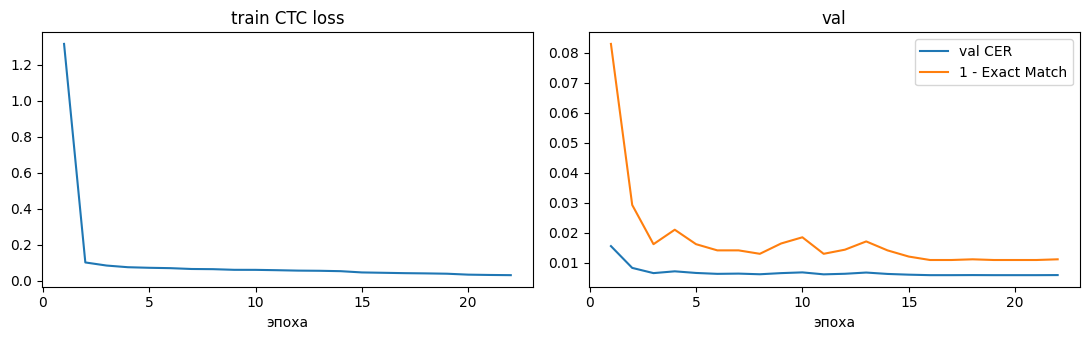

In [ ]:
h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(h.epoch, h.train_loss); ax[0].set_title("train CTC loss"); ax[0].set_xlabel("эпоха")
ax[1].plot(h.epoch, h.val_cer, label="val CER"); ax[1].plot(h.epoch, 1 - h.val_exact, label="1 - Exact Match")
ax[1].set_title("val"); ax[1].set_xlabel("эпоха"); ax[1].legend()
plt.tight_layout(); plt.savefig(OUT_DIR / "training_curves.png", dpi=120); plt.show()

## Шаг 7. Метрики CRNN на val
Грузим именно **лучший** вес с диска через тот же `CRNNReader`, которым будет пользоваться другой человек. Заодно это проверка, что сохранённый файл рабочий.

In [ ]:
reader = CRNNReader(str(WEIGHTS), device=str(DEVICE))
print("загружено из файла:", {k: v for k, v in reader.info.items() if k in ("epoch", "val_cer", "val_exact_match", "torch_version")})
val_paths = dfs["val"]["image"].tolist()
crnn_val_preds, crnn_val_conf = reader.read_batch_with_conf(val_paths)
crnn_val_metrics = compute_metrics(Y["val"], crnn_val_preds)
print(crnn_val_metrics)
assert abs(crnn_val_metrics["cer"] - reader.info["val_cer"]) < 1e-3, "метрика из файла не совпала с метрикой обучения: проверь предобработку"

загружено из файла: {'epoch': 16, 'val_cer': 0.00594704684317719, 'val_exact_match': 0.989010989010989, 'torch_version': '2.14.1+cu130'}
{'cer': 0.00594704684317719, 'char_acc': 0.9942430414120842, 'exact_match': 0.989010989010989, 'n': 4368, 'S': 203, 'D': 9, 'I': 7}


## Шаг 3б. PaddleOCR на val (запуск)
Тот же val, что и у CRNN (после шага 1б). Если ячейка падает, поставь `RUN_PADDLE = False` в шаге 0: в таблице будет написано, что прогон не запускался.

In [ ]:
paddle_on_val()

ок (en_PP-OCRv5_mobile_rec), 227 c, кропов: 4368
{'cer': 0.04768499660556687, 'char_acc': 0.953346911065852, 'exact_match': 0.7200091575091575, 'n': 4368, 'S': 1472, 'D': 246, 'I': 38}
примеры (сырое -> после нормализации -> эталон):
  'A001BO92'           -> A001BO92     | A001BO92
  'A001CX61'           -> A001CX61     | A001CX61
  'A001HY116'          -> A001HY116    | A001HY116
  'A001KK161'          -> A001KK161    | A001KK161
  'A001OT716'          -> A001OT716    | A001OT716
  'A003EY177'          -> A003EY177    | A003EY177
  'A003XT37'           -> A003XT37     | A003XT37
  'A003yx 763.'        -> A003YX763    | A003YX763


## Шаг 8. Таблица сравнения (val)

In [ ]:
def row(name, m, note=""):
    if m is None:
        return dict(модель=name, CER="—", **{"точность символов": "—", "Exact Match": "—"}, примечание=note)
    return dict(модель=name, CER=round(m["cer"], 4), **{"точность символов": round(m["char_acc"], 4),
                "Exact Match": round(m["exact_match"], 4)}, примечание=note)

table = pd.DataFrame([
    row("PaddleOCR (без дообучения)", paddle_val_metrics, PADDLE_STATUS),
    row("CRNN (своя)", crnn_val_metrics, TRAIN_STATUS),
])
display(table)
table.to_csv(OUT_DIR / "val_comparison.csv", index=False)

if paddle_val_metrics is None:
    WINNER = "CRNN"
    print("Вывод: PaddleOCR не считался, на val доступна только CRNN.")
else:
    WINNER = "CRNN" if crnn_val_metrics["cer"] <= paddle_val_metrics["cer"] else "PaddleOCR"
    a, b_ = crnn_val_metrics, paddle_val_metrics
    print(f"Вывод: на val лучше {WINNER}: CER CRNN {a['cer']:.4f} против {b_['cer']:.4f} у PaddleOCR, "
          f"Exact Match {a['exact_match']:.4f} против {b_['exact_match']:.4f}.")

,модель,CER,точность символов,Exact Match,примечание
0,PaddleOCR (без дообучения),0.0477,0.9533,0.720,"ок (en_PP-OCRv5_mobile_rec), 227 c, кропов: 4368"
1,CRNN (своя),0.0059,0.9942,0.989,"обучена, лучшая эпоха по val CER = 0.0059, все..."


Вывод: на val лучше CRNN: CER CRNN 0.0059 против 0.0477 у PaddleOCR, Exact Match 0.9890 против 0.7200.


## Шаг 9. Разбор ошибок на val (CRNN)
Что смотрим: самые частые замены символов (в том числе 0/O и 8/B), качество по яркости и резкости кропа (тёмные и размытые), и примеры: прочитано верно, ошибка в одном символе, номер целиком неверный.
Всё сохраняется в `ocr_outputs/`.

In [ ]:
from collections import Counter

def sub_pairs(ref, hyp):
    """список (эталон, прочитано) для замен, по выравниванию Левенштейна"""
    n, m = len(ref), len(hyp)
    d = [[0]*(m+1) for _ in range(n+1)]
    for i in range(n+1): d[i][0] = i
    for j in range(m+1): d[0][j] = j
    for i in range(1, n+1):
        for j in range(1, m+1):
            d[i][j] = min(d[i-1][j]+1, d[i][j-1]+1, d[i-1][j-1] + (ref[i-1] != hyp[j-1]))
    i, j, out = n, m, []
    while i > 0 and j > 0:
        if d[i][j] == d[i-1][j-1] + (ref[i-1] != hyp[j-1]):
            if ref[i-1] != hyp[j-1]: out.append((ref[i-1], hyp[j-1]))
            i -= 1; j -= 1
        elif d[i][j] == d[i-1][j] + 1: i -= 1
        else: j -= 1
    return out

val = dfs["val"].copy()
val["pred"] = crnn_val_preds; val["conf"] = crnn_val_conf
val["n_err"] = [sum(edit_ops(r, p)) for r, p in zip(val.text, val.pred)]
val["exact"] = val.n_err == 0

pairs = Counter(pp for r, p in zip(val.text, val.pred) for pp in sub_pairs(r, p))
print("Топ-15 замен (эталон -> прочитано):")
for (a, b_), c in pairs.most_common(15): print(f"  {a} -> {b_}: {c}")
for a, b_ in [("0", "O"), ("O", "0"), ("8", "B"), ("B", "8")]:
    print(f"  {a} -> {b_}: {pairs.get((a, b_), 0)}")

# яркость и резкость
gray = [np.asarray(Image.open(p).convert("L")) for p in val.image]
val["brightness"] = [g.mean() for g in gray]
val["sharpness"] = [cv2.Laplacian(g, cv2.CV_64F).var() for g in gray]
val["dark"] = val.brightness < val.brightness.quantile(0.1)
val["blurry"] = val.sharpness < val.sharpness.quantile(0.1)
def grp(mask, name):
    sub = val[mask]; m = compute_metrics(sub.text.tolist(), sub.pred.tolist())
    return dict(группа=name, кропов=len(sub), CER=round(m["cer"], 4), EM=round(m["exact_match"], 4))
display(pd.DataFrame([grp(val.index >= 0, "все"), grp(val.dark, "самые тёмные 10%"),
                      grp(val.blurry, "самые размытые 10%"), grp(~val.dark & ~val.blurry, "остальные")]))

val.to_csv(OUT_DIR / "val_predictions_crnn.csv", index=False)

Топ-15 замен (эталон -> прочитано):
  7 -> 8: 5
  9 -> 7: 5
  3 -> 5: 5
  5 -> 2: 4
  B -> P: 4
  9 -> 1: 4
  3 -> 0: 4
  7 -> 9: 4
  5 -> 0: 4
  0 -> 4: 3
  0 -> 7: 3
  9 -> 3: 3
  E -> P: 3
  E -> O: 3
  E -> B: 3
  0 -> O: 0
  O -> 0: 0
  8 -> B: 0
  B -> 8: 0


,группа,кропов,CER,EM
0,все,4368,0.0059,0.9890
1,самые тёмные 10%,437,0.0019,0.9908
2,самые размытые 10%,437,0.0014,0.9977
3,остальные,3640,0.0067,0.9882


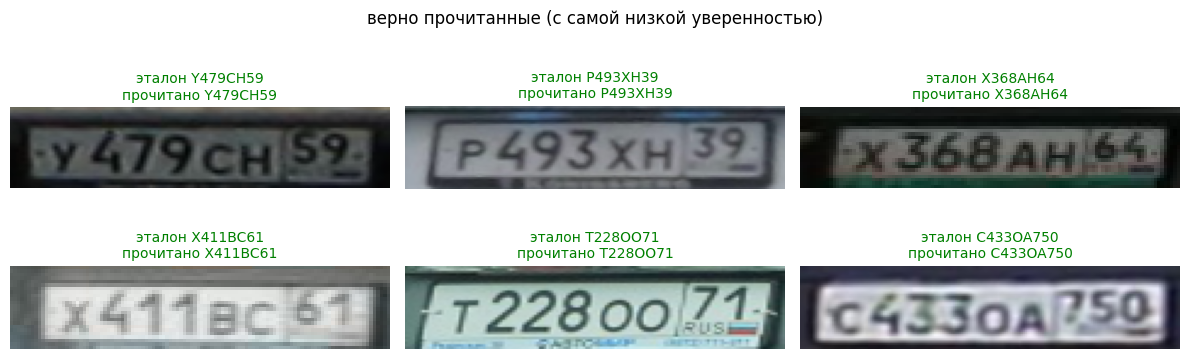

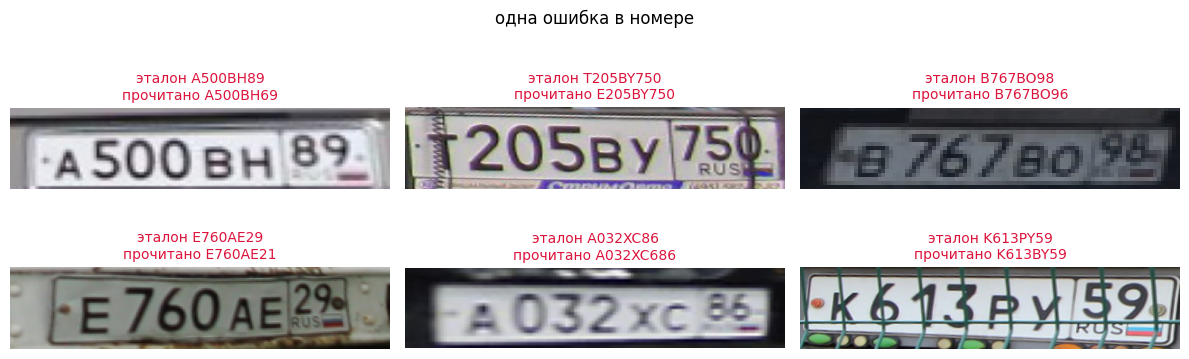

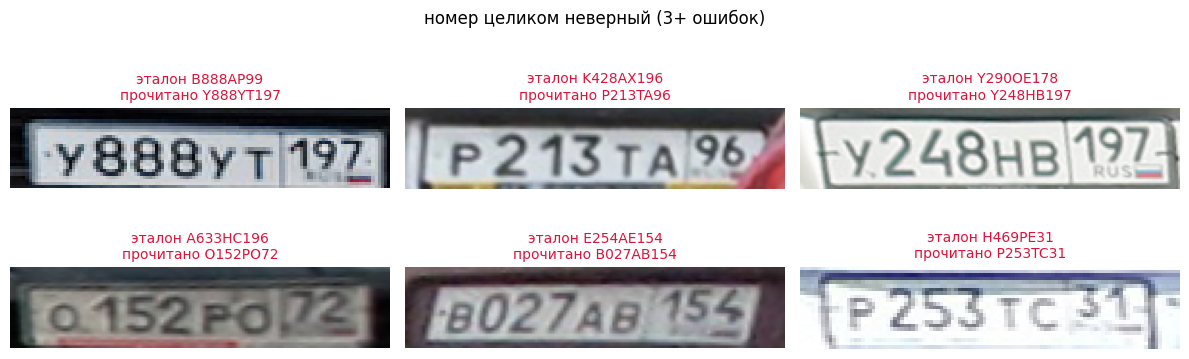

In [ ]:
def show(mask, title, k=6):
    sub = val[mask].sort_values("conf").head(k) if mask.any() else val.head(0)
    fig, axes = plt.subplots(2, 3, figsize=(12, 4.2))
    for ax in axes.ravel(): ax.axis("off")
    for ax, (_, r) in zip(axes.ravel(), sub.iterrows()):
        ax.imshow(Image.open(r.image).convert("RGB"))
        ax.set_title(f"эталон {r.text}\nпрочитано {r.pred}", fontsize=10, color="green" if r.exact else "crimson")
    fig.suptitle(title); plt.tight_layout(); plt.savefig(OUT_DIR / f"examples_{title.split()[0]}.png", dpi=110); plt.show()

show(val.exact, "верно прочитанные (с самой низкой уверенностью)")
show(val.n_err == 1, "одна ошибка в номере")
show(val.n_err >= 3, "номер целиком неверный (3+ ошибок)")

## Шаг 10. Test один раз
Считаем test только для модели, выбранной по val в шаге 8. По test ничего не подбираем. Чтобы нельзя было случайно прогнать повторно, результат кэшируется в `test_result.json`: если файл уже есть, повторный запуск ячейки только печатает сохранённое.

In [ ]:
TEST_FILE = OUT_DIR / "test_result.json"
if TEST_FILE.exists():
    test_res = json.loads(TEST_FILE.read_text())
    print("test уже считали, повторно не считаем:")
else:
    if WINNER == "CRNN":
        preds, _ = reader.read_batch_with_conf(dfs["test"]["image"].tolist())
    else:
        _, preds, _ = run_paddle(dfs["test"]["image"].tolist())      # победил PaddleOCR: test считаем для неё
    test_res = {"model": WINNER, "metrics": compute_metrics(Y["test"], preds)}
    TEST_FILE.write_text(json.dumps(test_res, ensure_ascii=False, indent=2))
print(test_res)

{'model': 'CRNN', 'metrics': {'cer': 0.00776845006891367, 'char_acc': 0.9925239109551852, 'exact_match': 0.982098982098982, 'n': 2849, 'S': 171, 'D': 8, 'I': 7}}


## Шаг 11. Что передать в часть 4 + архив для скачивания
Записываем `handoff.json`, кладём в архив **`smartparking_ocr_crnn.zip`**: веса, модуль `crnn_ocr.py`, метрики, кривые обучения, примеры ошибок и инструкцию.
Проверяем, что архив работает «с нуля»: распаковываем в пустую папку и читаем кроп.

In [ ]:
reason = (f"выбрана {WINNER} по val CER = {crnn_val_metrics['cer']:.4f}"
          + (f" (PaddleOCR {paddle_val_metrics['cer']:.4f})" if paddle_val_metrics else " (PaddleOCR не считался)")
          + "; выбор сделан по val, test использован один раз после выбора")
handoff = {"recognizer": WINNER, "weights": "crnn_best.pt", "module": "crnn_ocr.py", "alphabet": ALPHABET,
           "input": "уже вырезанный кроп номера, серый, 32x160 с сохранением пропорций",
           "val": crnn_val_metrics, "test": test_res["metrics"], "reason": reason, "paddle_status": PADDLE_STATUS}
(OUT_DIR / "handoff.json").write_text(json.dumps(handoff, ensure_ascii=False, indent=2))

USAGE = f"""# CRNN для чтения номера (SmartParking AI, часть 3)

Файлы: crnn_best.pt (веса), crnn_ocr.py (модель + предобработка + декодер).
Нужно: python 3.9+, torch, numpy, pillow.

    from crnn_ocr import CRNNReader
    reader = CRNNReader("crnn_best.pt")          # cuda, если есть, иначе cpu
    reader.read("crop.png")                      # 'A123BC77'
    reader.read_with_conf("crop.png")            # ('A123BC77', 0.98)
    reader.read_batch([img1, img2])              # список строк
    reader.read(cv2_crop, bgr=True)              # если кроп из cv2 (порядок BGR)

Вход: УЖЕ вырезанный номер (рамку ищет часть 2). Алфавит: {ALPHABET}. Выход: латиница без пробелов.
Метрики val: CER {crnn_val_metrics['cer']:.4f}, Exact Match {crnn_val_metrics['exact_match']:.4f}.
Метрики test: CER {test_res['metrics']['cer']:.4f}, Exact Match {test_res['metrics']['exact_match']:.4f}.
"""
(OUT_DIR / "README_usage.md").write_text(USAGE, encoding="utf-8")

ZIP = BASE / "smartparking_ocr_crnn.zip"
with zipfile.ZipFile(ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    z.write(WEIGHTS, "crnn_best.pt"); z.write("crnn_ocr.py", "crnn_ocr.py")
    for f in ("handoff.json", "README_usage.md", "history.csv", "val_comparison.csv", "val_predictions_crnn.csv",
              "test_result.json", "training_curves.png"):
        if (OUT_DIR / f).exists(): z.write(OUT_DIR / f, f)
    for f in OUT_DIR.glob("examples_*.png"): z.write(f, f.name)
print("архив:", ZIP, f"{ZIP.stat().st_size/1e6:.1f} МБ")
print(reason)

# проверка «с нуля»
chk = BASE / "_check_unzip"; shutil.rmtree(chk, ignore_errors=True); chk.mkdir()
zipfile.ZipFile(ZIP).extractall(chk)
r = subprocess.run([sys.executable, "-c",
    f"import sys; sys.path.insert(0, r'{chk}'); from crnn_ocr import CRNNReader; "
    f"rd = CRNNReader(r'{chk}/crnn_best.pt', device='cpu'); p = r'{dfs['test'].image.iloc[0]}'; print(rd.read_with_conf(p), 'эталон:', '{dfs['test'].text.iloc[0]}')"],
    capture_output=True, text=True)
print(r.stdout or r.stderr)
shutil.rmtree(chk, ignore_errors=True)

try:                                   # Google Colab: скачать архив на компьютер
    from google.colab import files
    files.download(str(ZIP))
except ImportError:
    from IPython.display import FileLink, display   # Kaggle / Jupyter: ссылка
    display(FileLink(str(ZIP.relative_to(BASE)) if ON_KAGGLE else str(ZIP)))

# Colab: сессия временная, поэтому копия на Google Drive страхует от потери весов
try:
    from google.colab import drive
    drive.mount("/content/drive")
    shutil.copy(ZIP, "/content/drive/MyDrive/smartparking_ocr_crnn.zip")
    print("копия сохранена на Google Drive: MyDrive/smartparking_ocr_crnn.zip")
except Exception as e:
    print("Drive пропущен:", e)

архив: /content/smartparking_ocr_crnn.zip 12.4 МБ
выбрана CRNN по val CER = 0.0059 (PaddleOCR 0.0477); выбор сделан по val, test использован один раз после выбора
('Y050TC77', 0.9569602683186531) эталон: A198OO77



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Drive пропущен: Error: credential propagation was unsuccessful


## Как потом пользоваться весами (для другого человека)
1. Скачать `smartparking_ocr_crnn.zip` (Kaggle: вкладка **Output** у версии ноутбука, либо `Data → Output` / файловый браузер справа).
2. Распаковать, положить `crnn_best.pt` и `crnn_ocr.py` рядом с кодом части 4. Поставить `torch numpy pillow`.
3. ```python
   from crnn_ocr import CRNNReader
   reader = CRNNReader("crnn_best.pt")
   print(reader.read("crop.png"))
   ```
Можно также залить архив на Kaggle как **Dataset** (*Output → New Dataset*) или на Hugging Face Hub, тогда ссылку можно дать любому.